# A5 – Relato y recomendaciones cuantificadas

## El relato en una frase

**RetailVenture no está empeorando: lleva dos años perdiendo margen siempre en los mismos tres sitios.** Esos sitios son el descuento online, las devoluciones de dos categorías y un marketing que no se puede medir.

- **Inicio (situación actual):** la gerencia cree que el margen cae. Los datos dicen otra cosa: el margen bruto, el ticket y las devoluciones están estables desde 2023 (sección 1). Lo único que cae es la conversión *registrada* de las campañas.
- **Nudo (hallazgos):**
  - el canal online regala el doble de descuento y el descuento no trae más ventas (A2);
  - Ropa y Electrónica devuelven mucho más que el resto (A3);
  - los clientes que se van son sobre todo compradores esporádicos (A3);
  - no hay forma de saber si las campañas generan ventas (A4).
- **Desenlace (recomendaciones):** cuatro medidas, ordenadas por el margen que recuperan, con su supuesto y su rango (secciones 2 a 6).

## Cómo cuantificamos

El enunciado pide cuantificar al menos tres recomendaciones con la forma: *"Si hacemos X, esperamos un incremento/reducción de Y% en Z métrica, equivalente a [monto] en ingresos"*.

Cada recomendación sale de un hallazgo de A2, A3 o A4. Para cada una damos:
- el hallazgo en el que se apoya,
- el supuesto del que depende la cifra (y por qué es razonable),
- un escenario central y un rango (escenarios prudente y optimista),
- el riesgo principal y, cuando hay inversión, el costo máximo con el que sigue siendo rentable.

Las cifras son **anuales con base 2024** (el último año completo), salvo R3, que actúa una sola vez sobre los clientes en riesgo de hoy. Montos en unidades monetarias (u. m.). Las decisiones están en `DECISIONES.md` (A5.1 a A5.5).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.carga import cargar_limpio, RAIZ
from src.powerbi import SALIDA, guardar

d = cargar_limpio()
cli = d["clientes"]
trx = d["transacciones"]
cam = d["campanas_marketing"]
dev = d["devoluciones"]
anio = trx[trx.fecha >= "2024-01-01"]
VENTAS, MARGEN = anio.monto_neto.sum(), anio.margen_bruto.sum()
FIG = RAIZ / "figures"

# Colores (paleta de referencia de la guía de visualización)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
TEXTO, TEXTO_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def miles(x):
    # 1.234 en vez de 1,234
    return f"{x:,.0f}".replace(",", ".")

def signo(x):
    return ("+" if x >= 0 else "−") + miles(abs(x))

print(f"Base 2024: ventas {miles(VENTAS)} | margen bruto {miles(MARGEN)} ({MARGEN / VENTAS:.1%})")
recomendaciones = []

Base 2024: ventas 8.684.581 | margen bruto 2.162.763 (24.9%)


## 1. Situación inicial: qué cambia y qué no

Las cuatro cifras que preocupan a la gerencia, trimestre a trimestre. Las devoluciones se miden por fecha de compra (A1.8).

trimestre                2023Q1  2023Q2  2023Q3  2023Q4  2024Q1  2024Q2  2024Q3  2024Q4
margen bruto %             24.6    24.7    24.7    24.6    25.4    24.9    24.7    24.7
ticket promedio           350.4   344.0   363.2   347.7   340.4   341.7   348.9   347.0
devoluciones %             13.2    13.6    13.0    13.8    13.3    13.3    13.8    13.5
conversión registrada %    11.3    12.3    11.2    10.2     7.9     6.8     7.1     5.6


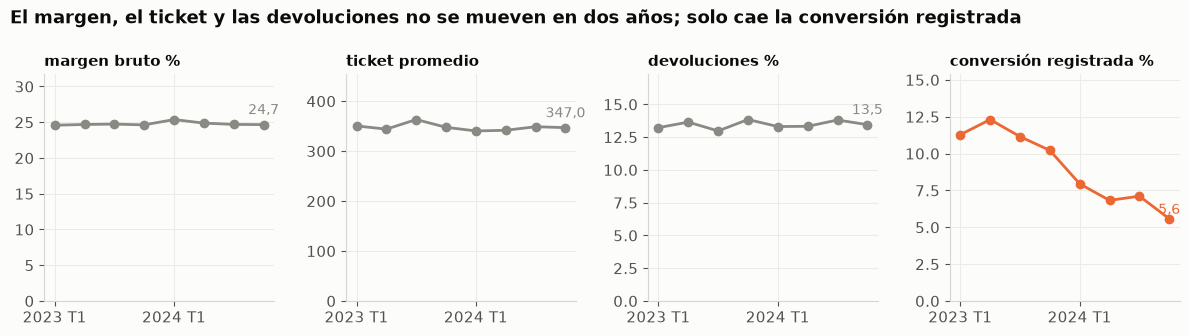

In [2]:
q = trx.groupby("trimestre").agg(ventas=("monto_neto", "sum"), margen=("margen_bruto", "sum"),
                                ticket=("monto_neto", "mean"), devolucion=("devuelta", "mean"))
situacion = pd.DataFrame({
    "margen bruto %": 100 * q.margen / q.ventas,
    "ticket promedio": q.ticket,
    "devoluciones %": 100 * q.devolucion,
    "conversión registrada %": 100 * cam.groupby(cam.fecha_envio.dt.to_period("Q").astype(str)).convertido.mean(),
})
situacion.index.name = "trimestre"
print(situacion.round(1).T.to_string())
guardar(situacion.reset_index(), "resultado_a5_situacion_trimestre")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
x = np.arange(len(situacion))
for ax, (col, fila), color in zip(axes, situacion.items(), [GRIS, GRIS, GRIS, NARANJA]):
    ax.plot(x, fila, marker="o", color=color, lw=2)
    ax.set_ylim(0, fila.max() * 1.25)
    ax.set_title(col, fontsize=11)
    ax.set_xticks(x[::4], [t.replace("Q", " T") for t in situacion.index[::4]])
    ax.text(x[-1], fila.iloc[-1] * 1.06, f"{fila.iloc[-1]:.1f}".replace(".", ","), ha="center", fontsize=10, color=color)
fig.suptitle("El margen, el ticket y las devoluciones no se mueven en dos años; solo cae la conversión registrada",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "a5_situacion_inicial.png", dpi=150)
plt.show()

**El inicio del relato:** el margen bruto se mantiene entre 24,6% y 25,4%, el ticket entre 340 y 363 u. m., y las devoluciones entre 13,0% y 13,8%. La "presión creciente" del enunciado no aparece. Lo que sí hay es un **nivel** de pérdidas que se repite cada trimestre. La única cifra que cae es la conversión registrada, y en A4 vimos que esa caída no se refleja en las compras.

## 2. R1. Alinear el descuento online con el de tienda y app (piloto)

**Hallazgos (A2.5):**
- Online da el doble de descuento que la tienda y la app (7,5% contra 3,7%) y es el canal con menor margen.
- Los descuentos no generan volumen: con más descuento se compran las mismas unidades por compra.
- Una compra con más descuento no hace volver antes al cliente (recompra a 90 días: +0,2 puntos por cada 10 de descuento; IC 95%: −0,4 a +0,9).
- El descuento cambia venta a venta, como si fuera al azar: no hay promociones.

**Qué proponemos:**
- que el descuento medio online sea el mismo que en tienda y app, con un tope por venta;
- que, en todos los canales, ninguna venta se haga por debajo del costo. Esto afecta sobre todo a Electrónica, la categoría con menos margen.

Se aplica primero como **piloto** en una parte de los productos online, comparando con el resto.

**Supuesto:** las ventas no cambian, porque el descuento no mueve ni las unidades ni la recompra (A2.5). **El riesgo:** solo vemos las ventas que ocurrieron. Si con menos descuento alguien deja de comprar online, no lo habríamos visto. Por eso calculamos cuántas ventas online se pueden perder antes de que la medida deje de compensar, y por eso es un piloto.

**Escenarios:** central = online iguala a tienda y app; prudente = se cierra la mitad de la brecha.

Descuento medio 2024: online 7.5% | tienda y app 3.7%
Margen bruto 2024: online 22.7% | tienda y app 26.2%
Online regala 274.235 en descuentos (57% del total)

Tope por venta online que iguala el descuento medio: 4.7% (afecta a 58% de las ventas online)
Ventas bajo costo en tienda y app (2024): 147, pérdida 5.093
Ingreso y margen extra al año: central 146.161 | prudente 77.325 | de Electrónica: 48%
Margen bruto online 2024: 740.822 -> 881.890 (+19.0%)
Compensa mientras online no pierda más del 16% de sus ventas


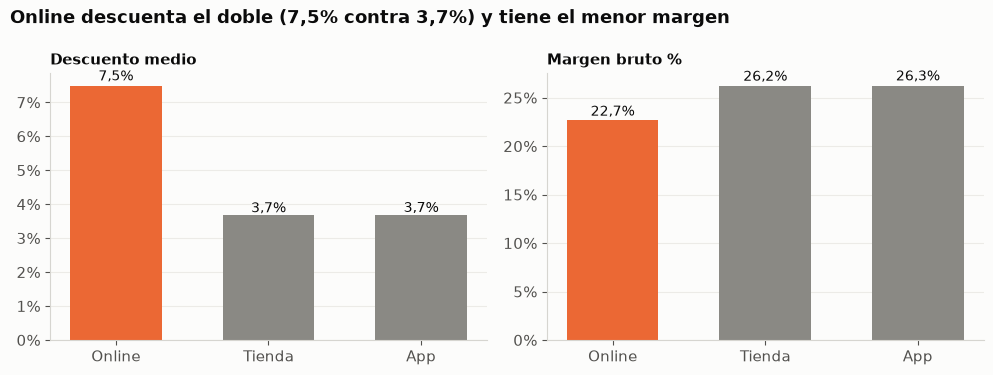

In [3]:
online = anio[anio.canal == "online"]
resto = anio[anio.canal != "online"]
d_resto = resto.descuento.mean()
bruto = online.cantidad * online.precio_unitario          # venta a precio de lista
print(f"Descuento medio 2024: online {online.descuento.mean():.1%} | tienda y app {d_resto:.1%}")
print(f"Margen bruto 2024: online {online.margen_bruto.sum() / online.monto_neto.sum():.1%} | "
      f"tienda y app {resto.margen_bruto.sum() / resto.monto_neto.sum():.1%}")
print(f"Online regala {miles(online.costo_descuento.sum())} en descuentos ({online.costo_descuento.sum() / anio.costo_descuento.sum():.0%} del total)")

def recorte(meta):
    # cada venta online con más descuento que 'meta' baja a 'meta'
    nuevo = np.minimum(online.descuento, meta)
    return ((online.descuento - nuevo) * bruto).sum()

# Buscamos el tope que deja el descuento medio online igual al de tienda y app
topes = np.linspace(0, 0.35, 701)
medias = [np.minimum(online.descuento, t).mean() for t in topes]
tope = topes[np.argmin(np.abs(np.array(medias) - d_resto))]
central_online = recorte(tope)
prudente_online = recorte(topes[np.argmin(np.abs(np.array(medias) - (online.descuento.mean() + d_resto) / 2))])
nuevo = np.minimum(online.descuento, tope)
assert ((bruto * (1 - nuevo) - online.costo_total) >= 0).all()   # con el tope, ninguna venta online queda bajo costo

# Ventas bajo costo en tienda y app: lo que se deja de perder si ninguna baja del costo
bajo_costo = -resto.loc[resto.bajo_costo, "margen_bruto"].sum()
central, prudente = central_online + bajo_costo, prudente_online + bajo_costo
de_electronica = (((online.descuento - nuevo) * bruto)[online.categoria == "Electrónica"].sum()
                  + -resto.loc[resto.bajo_costo & (resto.categoria == "Electrónica"), "margen_bruto"].sum())
print(f"\nTope por venta online que iguala el descuento medio: {tope:.1%} (afecta a {(online.descuento > tope).mean():.0%} de las ventas online)")
print(f"Ventas bajo costo en tienda y app (2024): {resto.bajo_costo.sum()}, pérdida {miles(bajo_costo)}")
print(f"Ingreso y margen extra al año: central {miles(central)} | prudente {miles(prudente)} | de Electrónica: {de_electronica / central:.0%}")

margen_online = online.margen_bruto.sum()
perdida_max = central_online / (margen_online + central_online)
print(f"Margen bruto online 2024: {miles(margen_online)} -> {miles(margen_online + central_online)} (+{central_online / margen_online:.1%})")
print(f"Compensa mientras online no pierda más del {perdida_max:.0%} de sus ventas")

recomendaciones.append(["R1", "Piloto: tope de " + f"{100 * tope:.1f}".replace(".", ",") + "% al descuento online y ninguna venta bajo costo",
                        "margen bruto total", central / MARGEN, central, prudente, central, central])

# Gráfico para el dashboard: descuento y margen por canal
c = anio.groupby("canal").agg(descuento=("descuento", "mean"), ventas=("monto_neto", "sum"), margen=("margen_bruto", "sum"))
c = c.assign(margen_pct=100 * c.margen / c.ventas, descuento=100 * c.descuento).reindex(["online", "tienda_fisica", "app_movil"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
nombres = ["Online", "Tienda", "App"]
for ax, col, fmt in [(a1, "descuento", "Descuento medio"), (a2, "margen_pct", "Margen bruto %")]:
    ax.bar(nombres, c[col], color=[NARANJA, GRIS, GRIS], width=0.6)
    for i, v in enumerate(c[col]):
        ax.text(i, v * 1.02, f"{v:.1f}%".replace(".", ","), ha="center", fontsize=10)
    ax.set_title(fmt, fontsize=11)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Online descuenta el doble ({c.descuento['online']:.1f}% contra {c.descuento['tienda_fisica']:.1f}%) y tiene el menor margen".replace(".", ","),
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "a5_online_descuento.png", dpi=150)
plt.show()

## 3. R2. Guía de tallas en Ropa, y buscar la causa del exceso de Electrónica

**Hallazgos (A3.1):**
- Solo dos categorías devuelven más de lo normal: Ropa y Calzado (21,8%) y Electrónica (17,7%), contra 10,3% del resto.
- En Ropa, una parte del exceso tiene una causa clara: la talla incorrecta, un motivo que solo existe en esa categoría.
- En Electrónica, el reparto de motivos es igual al del resto y ningún producto tiene más defectuosos de lo normal. Los datos no señalan una causa.

**Qué proponemos:**
- **Ropa:** guía de tallas y tabla de medidas en cada ficha. Es la parte que se puede cuantificar.
- **Electrónica (y el resto del exceso de Ropa):** antes de invertir, un diagnóstico. Por ejemplo, revisar una muestra de devoluciones y preguntar al cliente. Damos lo que está en juego como **techo**, no como estimación.

**Supuesto:** la guía evita una parte de las devoluciones por talla. No sabemos cuánta, así que damos escenarios de 25%, 50% y 75%. Cada devolución evitada es una venta que no se reembolsa. Como una prenda de talla equivocada se revende, se gana su margen (A2.1).

In [4]:
ropa = anio[anio.categoria == "Ropa_y_Calzado"]
talla = ropa[ropa.devuelta & (ropa.motivo_devolucion == "Talla_incorrecta")]
talla_ingreso, talla_margen = talla.monto_neto.sum(), (talla.margen_bruto - talla.margen_neto).sum()
print(f"Devoluciones por talla en 2024: {len(talla)} de {ropa.devuelta.sum()} devoluciones de Ropa "
      f"({len(talla) / ropa.devuelta.sum():.0%}) | {miles(talla_ingreso)} reembolsados, {miles(talla_margen)} de margen")

esc = {p: (p * talla_ingreso, p * talla_margen) for p in [0.25, 0.5, 0.75]}
for p, (i, m) in esc.items():
    print(f"  evitar el {p:.0%} de las devoluciones por talla: +{miles(i)} en ingresos, +{miles(m)} de margen")
dev_ropa = ropa[ropa.devuelta].monto_neto.sum()
print(f"Escenario central (50%): las devoluciones de Ropa bajan un {esc[0.5][0] / dev_ropa:.1%}")
print(f"Costo máximo de la guía para que compense: {miles(esc[0.5][1])} al año")

# Techo: todo el exceso de Ropa y Electrónica sobre la tasa del resto (misma base que A3.5)
DOS = ["Ropa_y_Calzado", "Electrónica"]
tasa_resto = anio[~anio.categoria.isin(DOS)].devuelta.mean()
techo_ingreso = techo_margen = techo_margen_prov = 0
for c in DOS:
    x = anio[anio.categoria == c]
    fraccion = 1 - tasa_resto / x.devuelta.mean()
    dv = x[x.devuelta]
    techo_ingreso += dv.monto_neto.sum() * fraccion
    techo_margen += (dv.margen_bruto - dv.margen_neto).sum() * fraccion
    techo_margen_prov += dv.margen_bruto.sum() * fraccion
print(f"\nTecho (todo el exceso de Ropa y Electrónica, 2024): {miles(techo_ingreso)} en ingresos; "
      f"margen de {miles(techo_margen_prov)} a {miles(techo_margen)} según quién asuma los defectuosos")
# El techo es el doble de la cifra a 6 meses de A3.5 (misma base)
a3 = pd.read_csv(SALIDA / "resultado_a3_impacto_6_meses.csv", index_col=0)
assert abs(a3.loc["Exceso de devoluciones de Ropa y Electrónica", "ingresos"] * 2 - techo_ingreso) < 1

recomendaciones.append(["R2", "Guía de tallas en Ropa (y diagnóstico de las devoluciones de Electrónica)",
                        "devoluciones de Ropa", -esc[0.5][0] / dev_ropa, esc[0.5][0], esc[0.25][0], esc[0.75][0], esc[0.5][1]])

Devoluciones por talla en 2024: 140 de 904 devoluciones de Ropa (15%) | 26.733 reembolsados, 10.599 de margen
  evitar el 25% de las devoluciones por talla: +6.683 en ingresos, +2.650 de margen
  evitar el 50% de las devoluciones por talla: +13.367 en ingresos, +5.300 de margen
  evitar el 75% de las devoluciones por talla: +20.050 en ingresos, +7.949 de margen
Escenario central (50%): las devoluciones de Ropa bajan un 8.3%
Costo máximo de la guía para que compense: 5.300 al año

Techo (todo el exceso de Ropa y Electrónica, 2024): 370.164 en ingresos; margen de 70.467 a 161.647 según quién asuma los defectuosos


## 4. R3. Reactivar a los clientes recurrentes en riesgo, con grupo de control

**Hallazgos:**
- **A3.4:** hay 1.388 clientes recurrentes (2 o más compras) que llevan más de 180 días sin comprar. Si no vuelven, la empresa deja de ingresar unas 187.600 u. m. en los próximos 6 meses. El 79% de ese valor está en clientes del segmento Esporádico.
- **A4.3:** no hay pruebas de que las campañas actuales generen compras.

**Qué proponemos:** una campaña de reactivación para estos clientes, que se pueden identificar hoy con sus compras y su última fecha de compra, **dejando un grupo de control**: un 20% elegido al azar que no la recibe. Así, por primera vez, se mide si una campaña genera ventas comparando con quien no la recibió.

**Supuesto:** no sabemos cuánto recupera una campaña, y los datos actuales no permiten estimarlo. Damos escenarios de 5%, 10% y 20% de los ingresos en riesgo. Es una cifra **a 6 meses y de una sola vez**: actúa sobre los clientes en riesgo de hoy, así que no se multiplica por dos para anualizarla. El valor seguro de esta recomendación es la medición.

In [5]:
riesgo_6m = a3.loc["Clientes recurrentes en riesgo que no vuelven", "ingresos"]   # notebook 03, A3.5
margen_pct = MARGEN / VENTAS
esc = {p: p * riesgo_6m for p in [0.05, 0.10, 0.20]}
for p, v in esc.items():
    print(f"  recuperar el {p:.0%} de lo que está en riesgo: +{miles(v)} en ingresos en 6 meses (+{miles(v * margen_pct)} de margen)")
print(f"Costo máximo de la campaña para que compense (escenario central): {miles(esc[0.10] * margen_pct)}")

recomendaciones.append(["R3", "Campaña de reactivación a los clientes recurrentes en riesgo, con 20% de grupo de control",
                        "ingresos de los clientes recurrentes en riesgo", 0.10, esc[0.10], esc[0.05], esc[0.20], esc[0.10] * margen_pct])

  recuperar el 5% de lo que está en riesgo: +9.380 en ingresos en 6 meses (+2.336 de margen)
  recuperar el 10% de lo que está en riesgo: +18.760 en ingresos en 6 meses (+4.672 de margen)
  recuperar el 20% de lo que está en riesgo: +37.519 en ingresos en 6 meses (+9.344 de margen)
Costo máximo de la campaña para que compense (escenario central): 4.672


## 5. R4. Limitar el descuento de las campañas al 5%

**Hallazgo (A4.5):**
- Aunque aceptemos la marca de conversión, las conversiones extra que trae el descuento no pagan el descuento que se regala a todas las conversiones. Solo el 5% se paga solo; de 10% en adelante, cada envío pierde margen.
- Según las compras reales, el descuento no cambia nada.

**Qué proponemos:** que ninguna campaña ofrezca más de 5% de descuento.

**Supuesto:** usamos la lectura más favorable al descuento, la marca de conversión de A4.
- Cada conversión se valora con el ticket y el margen de las compras coincidentes (355 u. m. y 23,4%). Es casi el ticket de cualquier compra (344–351), así que no depende de que esas compras sean coincidencias.
- Con la lectura de las compras reales, el ahorro sería mayor, porque todo el descuento de campaña sería costo sin retorno.
- La conversión registrada bajaría, y hay que avisarlo para que no se lea como un fracaso.

In [6]:
pares = cam[cam.conversion_respaldada][["campana_id", "cliente_id", "fecha_envio"]].merge(
    trx[["cliente_id", "fecha", "monto_neto", "margen_bruto"]], on="cliente_id")
pares = pares[(pares.fecha - pares.fecha_envio).dt.days.between(0, 30)].sort_values("fecha").drop_duplicates("campana_id")
ticket, mpct = pares.monto_neto.mean(), pares.margen_bruto.sum() / pares.monto_neto.sum()
conv = cam.groupby("descuento_ofrecido").convertido.mean()
neto = (conv - conv[0]) * ticket * mpct - conv * conv.index * ticket       # margen por envío frente a 0% de descuento
envios = cam[cam.fecha_envio.dt.year == 2024].descuento_ofrecido.value_counts()
actual = (neto * envios).sum()
con_tope = neto[0.05] * envios[envios.index >= 0.05].sum()
ahorro = con_tope - actual
print(f"Ticket de las compras coincidentes: {ticket:.0f} | de todas las compras 2024: {anio.monto_neto.mean():.0f}")
print("Margen por envío frente a no dar descuento (según la marca):", neto.round(2).to_dict())
print(f"Envíos 2024 con más de 5%: {envios[envios.index > 0.05].sum()} de {envios.sum()}")
print(f"Margen de las campañas 2024: actual {miles(actual)} | con tope de 5%: {miles(con_tope)} | diferencia +{miles(ahorro)}")
regalado = (cam[(cam.fecha_envio.dt.year == 2024)].pipe(lambda c: (c.convertido * c.descuento_ofrecido).sum()) * ticket)
regalado_5 = (cam[(cam.fecha_envio.dt.year == 2024)].pipe(lambda c: (c.descuento_ofrecido.clip(upper=0.05) > 0).mul(conv[0.05]).sum()) * 0.05 * ticket)
print(f"Descuento regalado en campañas 2024: {miles(regalado)} -> {miles(regalado_5)} con el tope")
print(f"Conversión registrada esperada: cae de {conv[conv.index > 0.05].mean():.1%} a {conv[0.05]:.1%} en los envíos que hoy tienen más de 5%")

# Ingresos registrados (según la marca): conversiones × ticket × (1 − descuento). Con menos descuento hay menos conversiones.
altos = envios[envios.index > 0.05]
ingresos_cambio = sum(n * (conv[0.05] * ticket * 0.95 - conv[k] * ticket * (1 - k)) for k, n in altos.items())
print(f"Ingresos registrados por campañas: {'+' if ingresos_cambio > 0 else '−'}{miles(abs(ingresos_cambio))} al año (menos conversiones)")

recomendaciones.append(["R4", "Tope de 5% al descuento de las campañas", "descuento regalado en campañas",
                        -(regalado - regalado_5) / regalado, ingresos_cambio, ingresos_cambio, ingresos_cambio, ahorro])

Ticket de las compras coincidentes: 355 | de todas las compras 2024: 344
Margen por envío frente a no dar descuento (según la marca): {0.0: 0.0, 0.05: 0.25, 0.1: -0.08, 0.15: -1.07, 0.2: -2.88, 0.25: -4.9}
Envíos 2024 con más de 5%: 2914 de 4452
Margen de las campañas 2024: actual -6.266 | con tope de 5%: 931 | diferencia +7.197
Descuento regalado en campañas 2024: 16.415 -> 4.507 con el tope
Conversión registrada esperada: cae de 10.6% a 6.9% en los envíos que hoy tienen más de 5%
Ingresos registrados por campañas: −21.737 al año (menos conversiones)


## 6. Resumen: las recomendaciones en el formato del enunciado

In [7]:
r = pd.DataFrame(recomendaciones, columns=["id", "qué hacemos", "métrica", "cambio en la métrica", "ingresos (central)",
                                           "desde", "hasta", "margen (central)"]).set_index("id")
r["periodo"] = ["al año", "al año", "en 6 meses, una vez", "al año"]
r = r.sort_values("margen (central)", ascending=False)
for i, f in r.iterrows():
    verbo = "un incremento" if f["cambio en la métrica"] > 0 else "una reducción"
    print(f"{i}. Si hacemos «{f['qué hacemos']}», esperamos {verbo} de {abs(f['cambio en la métrica']):.1%} en {f['métrica']}, "
          f"equivalente a {signo(f['ingresos (central)'])} en ingresos {f['periodo']}" +
          (f" (rango {miles(f['desde'])} a {miles(f['hasta'])})" if f["desde"] != f["hasta"] else "") +
          f" y {signo(f['margen (central)'])} de margen.")
total = r["margen (central)"].sum()
print(f"\nTotal central: {miles(r['ingresos (central)'].sum())} en ingresos y {miles(total)} de margen "
      f"({total / MARGEN:.1%} del margen bruto de 2024). R1 es el {r.loc['R1', 'margen (central)'] / total:.0%}.")
print(f"Aparte, el techo del exceso de devoluciones (si el diagnóstico encuentra la causa): {miles(techo_ingreso)} en ingresos al año.")
guardar(r.reset_index(), "resultado_a5_recomendaciones")

R1. Si hacemos «Piloto: tope de 4,7% al descuento online y ninguna venta bajo costo», esperamos un incremento de 6.8% en margen bruto total, equivalente a +146.161 en ingresos al año (rango 77.325 a 146.161) y +146.161 de margen.
R4. Si hacemos «Tope de 5% al descuento de las campañas», esperamos una reducción de 72.5% en descuento regalado en campañas, equivalente a −21.737 en ingresos al año y +7.197 de margen.
R2. Si hacemos «Guía de tallas en Ropa (y diagnóstico de las devoluciones de Electrónica)», esperamos una reducción de 8.3% en devoluciones de Ropa, equivalente a +13.367 en ingresos al año (rango 6.683 a 20.050) y +5.300 de margen.
R3. Si hacemos «Campaña de reactivación a los clientes recurrentes en riesgo, con 20% de grupo de control», esperamos un incremento de 10.0% en ingresos de los clientes recurrentes en riesgo, equivalente a +18.760 en ingresos en 6 meses, una vez (rango 9.380 a 37.519) y +4.672 de margen.

Total central: 156.550 en ingresos y 163.329 de margen (7.6%

## Notas

- **Orden de prioridad (por margen):** R1 (descuento online), R4 (descuento de campañas), R2 (tallas) y R3 (reactivación con control). Juntas **podrían recuperar hasta** el total de la tabla en el escenario central. Son escenarios, no promesas.
- **R1 es la que más pesa y la más segura, pero no es segura del todo.** No requiere inversión y se apoya en un hallazgo comprobado de varias formas (A2.5), incluida la recompra. Su riesgo es que el descuento mueva ventas online que no vemos: compensa mientras online no pierda más del 16% de sus ventas. Por eso es un piloto. Casi la mitad del beneficio viene de Electrónica, la categoría con menos margen.
- **R2 es pequeña porque solo cuantificamos lo que tiene causa.** La talla explica una parte del exceso de Ropa. El resto del exceso de Ropa y todo el de Electrónica (el techo) no tiene una causa visible en los datos. Prometer que unas fichas mejores lo reducen sería inventar. El primer paso es el diagnóstico.
- **R3 es sobre todo una forma de medir.** Su valor seguro es que, con grupo de control, la empresa sabrá por fin si sus campañas generan ventas (A4.3). Las cifras son escenarios, no una estimación.
- **R4 es pequeña en dinero,** pero evita regalar descuento sin retorno. Hace caer la conversión registrada (de 10,6% a 6,9% en esos envíos), lo que hay que avisar para que no se lea como un fracaso.
- **Costos:** R2 y R3 tienen costos que no conocemos (la guía de tallas, la campaña). Por eso damos el costo máximo con el que cada una sigue compensando. R1 y R4 no requieren inversión.
- **No sumamos solapamientos importantes:** R1 actúa sobre el precio de las ventas online y las ventas bajo costo, R2 sobre las devoluciones por talla, R3 sobre clientes que hoy no compran y R4 sobre el descuento de campaña.